# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [3]:
plans.head(5)
# mostrar las primeras 5 filas de plans

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
usage.head(5)
# mostrar las primeras 5 filas de usage

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().count())
print(users.isna().count()/users.size)

user_id       4000
first_name    4000
last_name     4000
age           4000
city          4000
reg_date      4000
plan          4000
churn_date    4000
dtype: int64
user_id       0.125
first_name    0.125
last_name     0.125
age           0.125
city          0.125
reg_date      0.125
plan          0.125
churn_date    0.125
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().count())

id          40000
user_id     40000
type        40000
date        40000
duration    40000
length      40000
dtype: int64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

COMENTARIO
Los 4000 registros corresponden al 12.5% del total, lo que significa que se debe investigar más a fondo antes de tomar una decisión en su tratamiento.


💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?  
- Indica qué harías: ¿imputar, eliminar, ignorar?

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` muestra una distribución simétrica.
- La columna `age` muestra un sesgo a la derecha, además de la existencia de un valor sentinela "-999".

In [13]:
# explorar columnas numéricas de usage
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe qué ves.
- Las columnas ...

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
for col in columnas_user:
    print(users[col].describe())
    print(users[col].unique())

    

count       3531
unique         7
top       Bogotá
freq         808
Name: city, dtype: object
['Medellín' '?' 'CDMX' 'Bogotá' 'GDL' 'MTY' nan 'Cali']
count       4000
unique         2
top       Basico
freq        2595
Name: plan, dtype: object
['Basico' 'Premium']


- La columna `city` incluye 7 categorías, dos de ellas quivalentes entre si, con valores sentinela "?" y "nan". La moda es "Bogotá", con 808 registros. Esta columna presenta 469 registros inválidos además de los sentinels.
- La columna `plan` consiste en 2 categorías normales, la moda es "Basico" con 2595 registros.

In [15]:
# explorar columna categórica de usage
print(usage['type'].describe())
print(usage['type'].unique())
# completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object
['call' 'text']


- La columna `type` contiene 2 categorías, el tipo más común es "text", aunque la distribución no es demasiado sesgada.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?  
- ¿Qué acción tomarías?  

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors = "coerce")
# completa el código


In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors = "coerce")
# completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users["reg_date"].dt.year
users["reg_date"].dt.year.unique()

array([2022, 2026, 2023, 2024])

COMENTARIO
En `reg_date`, se encuentran fechas de 2022 a 2024 y de 2026, en el contexto del ejercicio el año 2026 no ha transcurrido aún. Debemos clarificar si son entradas erróneas que se pueden corregir o si se pueden eliminar para estabilizar las medidas. También es posible que se analicen sólo relaciones en 2024 para que haya coherencias con los datos en la base "usage".

In [19]:
# Revisar los años presentes en `date` de usage
usage["date"].dt.year
usage["date"].dt.year.unique()

array([2024.,   nan])

En `date`, sólo podemos ver fechas del año 2024.
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- ¿Qué harías con ellas?

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users["age"].median()
users['age'] = users["age"].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users["city"] = users["city"].replace("?", pd.NA)

# Verificar cambios
users['city'].unique()

array(['Medellín', <NA>, 'CDMX', 'Bogotá', 'GDL', 'MTY', nan, 'Cali'],
      dtype=object)

In [22]:
# Marcar fechas futuras como NA para reg_date
hoy = pd.Timestamp.today()
users.loc[users['reg_date'] > hoy, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].describe()

count                    4000
unique                   3961
top       2026-05-10 00:00:00
freq                       40
first     2022-01-01 00:00:00
last      2026-05-10 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration"].isna().groupby(usage["type"]).mean().sort_values(ascending = False)

type
text    0.999276
call    0.000000
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage["length"].isna().groupby(usage["type"]).mean().sort_values(ascending = False)

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquí y escribe que tu diagnostico de nulos en `duration` y `length`:

Los nulos para "duration" corresponden con los registros de tipo "call", mientras que los nulos para "length" corresponden a los registros de tipo "text". Esto indica un patrón MNAR, donde "duration" podría ser el tamaño del texto y "length" la duración de la llamada (aunque uno esperaría lo contrario).

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int)
cant_mensajes = usage["is_text"].sum() #conocer el total de mensajes

usage["is_call"] = (usage["type"] == "call").astype(int)
cant_llamadas = usage["is_call"].sum() #conocer el total de llamadas

# Agrupar información por usuario
usage_agg = usage.groupby("user_id", dropna = False).agg({"is_text":"sum", "is_call":"sum", "length":"sum"}).reset_index()


# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,length
0,10000,7,3,258.0
1,10001,5,10,226.0
2,10002,5,2,225.0


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns = {"is_text":"cant_mensajes", "is_call":"cant_llamadas", "length":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,258.0
1,10001,5,10,226.0
2,10002,5,2,225.0


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users, usage_agg, on = ["user_id"], how = "left")
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,258.0
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,226.0
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,225.0
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,530.0
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,229.0


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
num_cols = ["age", "cant_mensajes", "cant_llamadas", "cant_minutos_llamada"]
user_profile[num_cols].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,288.128032
std,17.690408,2.358416,2.144238,180.906841
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,184.000000
50%,47.000000,5.000000,4.000000,268.000000
75%,63.000000,7.000000,6.000000,361.000000
max,79.000000,17.000000,15.000000,2028.000000


In [29]:

# Distribución porcentual del tipo de plan
plan_types = ['Basico', 'Premium']
for plan in plan_types:
    print("Cantidad de usuarios con plan:", plan)
    print(len(user_profile[user_profile["plan"] == plan]))


Cantidad de usuarios con plan: Basico
2595
Cantidad de usuarios con plan: Premium
1405


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

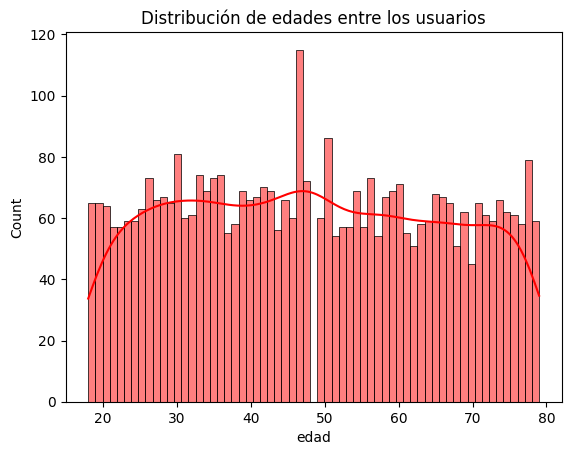

In [30]:
# Histograma para visualizar la edad (age)
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(user_profile["age"], bins = 63, color = "red", kde = True)
plt.xlabel("edad")
plt.title("Distribución de edades entre los usuarios")
plt.show()

💡Insights: 
- Distribución simétrica bastante pareja con un pico a los 46 años y un valle sin regisros a los 49.
- Hay otros picos para las edades de 30 y 75 años.

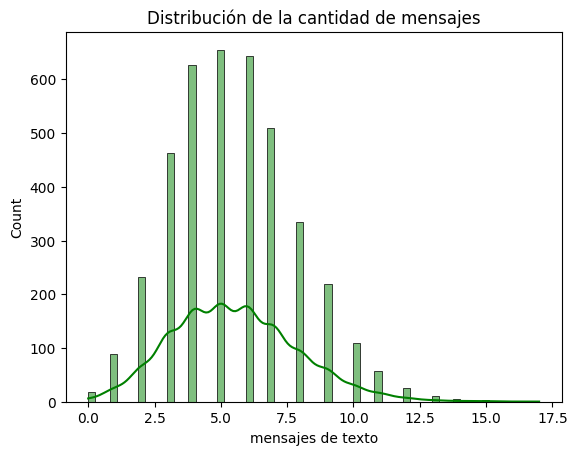

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(user_profile["cant_mensajes"], bins = 63, color = "green", kde = True)
plt.xlabel("mensajes de texto")
plt.title("Distribución de la cantidad de mensajes")
plt.show()

💡Insights: 
- Distribución sesgada a la derecha que representa una minoría de clientes que envía muchos más mensajes que el promedio.

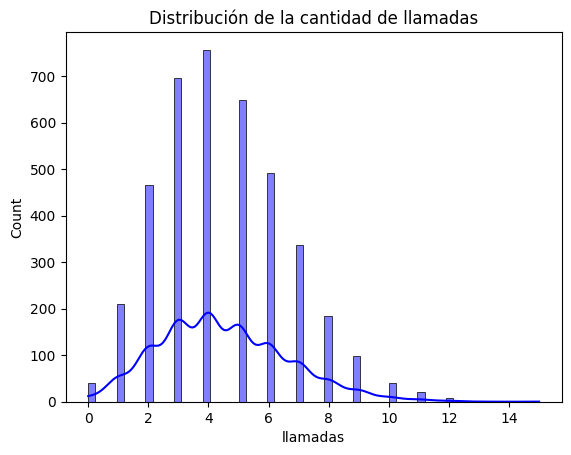

In [32]:
# Histograma para visualizar la cant_llamadas

sns.histplot(user_profile["cant_llamadas"], bins = 63, color = "blue", kde = True)
plt.xlabel("llamadas")
plt.title("Distribución de la cantidad de llamadas")
plt.show()


💡Insights: 
- Distribución normal con sesgo a la derecha que representa una minoría de usuarios que hace más llamadas de lo normal.

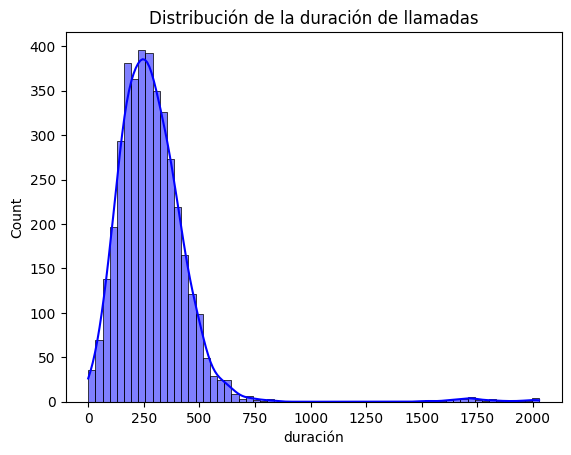

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(user_profile["cant_minutos_llamada"], bins = 63, color = "blue", kde = True)
plt.xlabel("duración")
plt.title("Distribución de la duración de llamadas")
plt.show()


💡Insights: 
- Distribución normal con sesgo a la derecha que representa una minoría de usuarios que hacen llamdas más largas de lo normal.
- La diferencia entre la mayoría de registros y la cola es mucho más pronunciada que en otras características.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

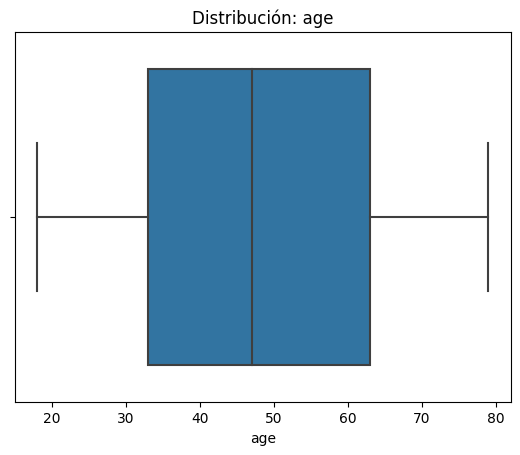

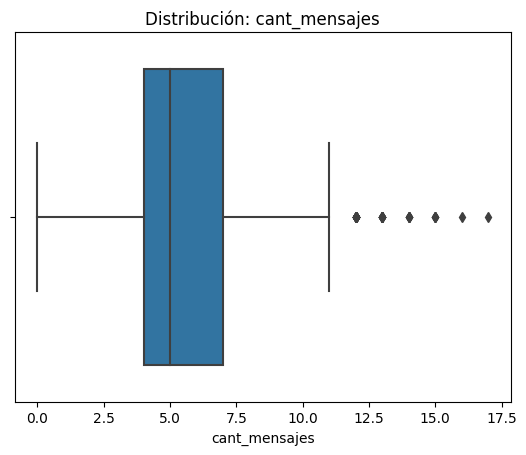

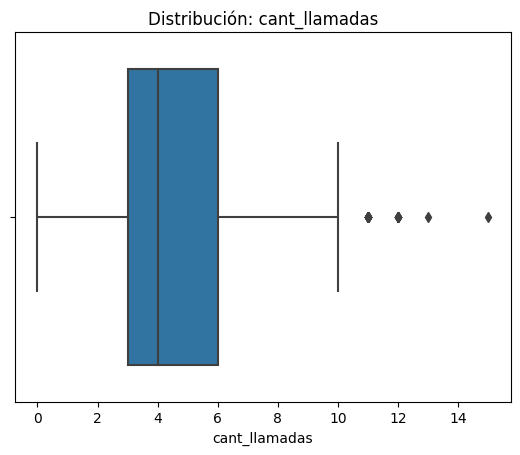

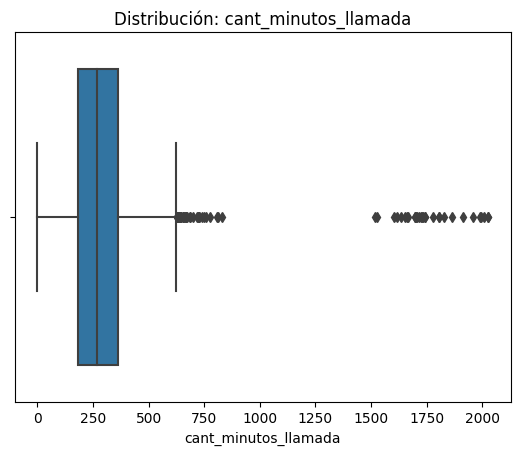

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data = user_profile, x = col)
    plt.title(f"Distribución: {col}")
    plt.show()

In [35]:

# Calcular límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
Q1 = {}
Q3 = {}
IQR = {}
Lim_Min = {}
Lim_Max = {}
for col in columnas_limites:
    Q1[col] = user_profile[col].quantile(0.25)
    Q3[col] = user_profile[col].quantile(0.75)
    IQR[col] = Q3[col] - Q1[col]
    Lim_Min[col] = Q1[col] - 1.5*IQR[col]
    Lim_Max[col] = Q3[col] + 1.5*IQR[col]

print("Q1")
print(Q1)
print("Q3")
print(Q3)
print("IQR")
print(IQR)
print("Limite inferior")
print(Lim_Min)
print("Limite superior")
print(Lim_Max)

Q1
{'age': 33.0, 'cant_mensajes': 4.0, 'cant_llamadas': 3.0, 'cant_minutos_llamada': 184.0}
Q3
{'age': 63.0, 'cant_mensajes': 7.0, 'cant_llamadas': 6.0, 'cant_minutos_llamada': 361.0}
IQR
{'age': 30.0, 'cant_mensajes': 3.0, 'cant_llamadas': 3.0, 'cant_minutos_llamada': 177.0}
Limite inferior
{'age': -12.0, 'cant_mensajes': -0.5, 'cant_llamadas': -1.5, 'cant_minutos_llamada': -81.5}
Limite superior
{'age': 108.0, 'cant_mensajes': 11.5, 'cant_llamadas': 10.5, 'cant_minutos_llamada': 626.5}


In [36]:

user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.122250,5.524381,4.478120,288.128032
std,17.690408,2.358416,2.144238,180.906841
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,184.000000
50%,47.000000,5.000000,4.000000,268.000000
75%,63.000000,7.000000,6.000000,361.000000
max,79.000000,17.000000,15.000000,2028.000000


In [37]:
user_profile[user_profile["cant_minutos_llamada"] == 2028]

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
3139,13139,Mariana,Torres,20.0,MTY,2024-05-09 12:23:13.548387104,Basico,NaN,10.0,8.0,2028.0


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
# En cant_mensajes se presenta un límite muy cercano al máximo definido por el método IQR, reforzando la condición de que son comportamiento naturales por parte de susuarios intensivos, como infirió a partir de la inspección visual de los datos. Se mantendrán los outliers sin capearlos ya que su efecto sobre el promedio es reducido.
- cant_llamadas: mantener o no outliers, porqué?
# El máximo del dataset y el límite calculado con IQR son bastante cercanos, lo cual también se vió reflejado en el histograma y boxplot. Dado que éstos outliers representan el comportamiento natural de usuarios, se deben mantener; pues su efecto sobre la media no es de gran magnitud.
- cant_minutos_llamada: mantener o no outliers, porqué?
# Los outliers en esta columna deben eliminarse ya que corresponden a más de tres veces el límite establecido por el IQR, lo cual en conjunción con el análisis gráfico nos muestra que no corresponden a comportamientos naturales del usuario. Se consideró la posibilidad de que correspondieran a datos de clientes corporativos pero se descarta al analizar de forma particular los registros que presentan estas duraciones de llamadas extremas; concluyéndose que corresponden a errores de captura.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [38]:
# Crear columna grupo_uso
def Grupos_uso(row):
    Calls = row["cant_llamadas"]
    Texts = row["cant_mensajes"]
    if pd.isna(Calls) or pd.isna(Texts):
        return "Error en registro"
    if Calls < 5 and Texts < 5:
        return "Bajo Uso"
    elif Calls < 10 and Texts < 10:
        return "Uso Medio"
    else:
        return "Alto uso"
    
user_profile["grupo_uso"] = user_profile.apply(Grupos_uso, axis = 1)
user_profile[["cant_llamadas", "cant_mensajes", "grupo_uso"]]

,cant_llamadas,cant_mensajes,grupo_uso
0,3.0,7.0,Uso Medio
1,10.0,5.0,Alto uso
2,2.0,5.0,Uso Medio
3,3.0,11.0,Alto uso
4,3.0,4.0,Bajo Uso
...,...,...,...
3995,3.0,6.0,Uso Medio
3996,3.0,4.0,Bajo Uso
3997,3.0,5.0,Uso Medio
3998,6.0,6.0,Uso Medio


In [39]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,258.0,Uso Medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,226.0,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,225.0,Uso Medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,530.0,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,229.0,Bajo Uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [40]:
# Crear columna grupo_edad
def Grupos_edad(row):
    Age = row["age"]
    if pd.isna(Age):
        return "Error en registro"
    if Age < 30:
        return "Joven"
    elif Age < 60:
        return "Adulto"
    else:
        return "Adulto mayor"
    
user_profile["grupo_edad"] = user_profile.apply(Grupos_edad, axis = 1)
user_profile[["age", "grupo_edad"]]

,age,grupo_edad
0,38.0,Adulto
1,53.0,Adulto
2,57.0,Adulto
3,69.0,Adulto mayor
4,63.0,Adulto mayor
...,...,...
3995,60.0,Adulto mayor
3996,24.0,Joven
3997,58.0,Adulto
3998,57.0,Adulto


In [44]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,258.0,Uso Medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,226.0,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,225.0,Uso Medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,530.0,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,229.0,Bajo Uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

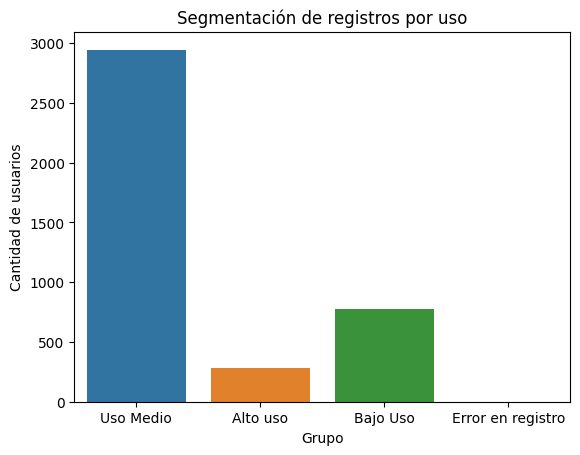

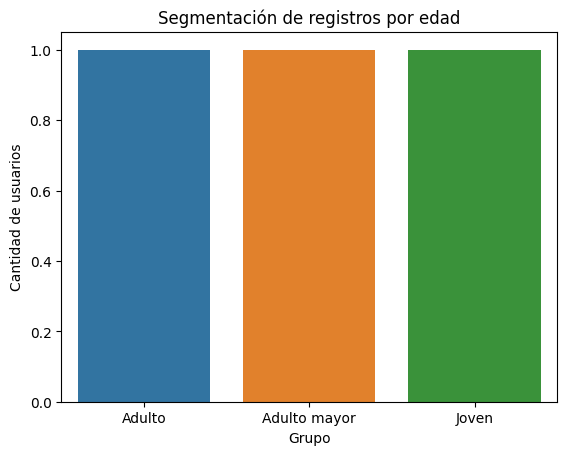

In [51]:

# Visualización de los segmentos por uso
sns.countplot(data = user_profile, x= user_profile["grupo_uso"])

plt.xlabel("Grupo")
plt.ylabel("Cantidad de usuarios")
plt.title("Segmentación de registros por uso")
plt.show()


sns.countplot(data = user_profile, x= user_profile["grupo_edad"])
plt.xlabel("Grupo")
plt.ylabel("Cantidad de usuarios")
plt.title("Segmentación de registros por edad")

plt.show()


In [ ]:
# Visualización de los segmentos por edad



---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- abc
- abc


🔍 **Segmentos por Edad**
- abc
- abc 


📊 **Segmentos por Nivel de Uso**
- abc
- abc


➡️ Esto sugiere que ...


💡 **Recomendaciones**
- abc
- abc 

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`